# BM25, dense, RRF fusion and cross-encoder reranking: a retrieval ablation you can rerun

This notebook builds seven retrievers over the same structure-aware chunks and scores them against gold passages: BM25 with a statute-aware tokenizer, two dense embedding models, reciprocal rank fusion of BM25 and dense results, and a cross-encoder that reranks the top 20. You get every component in plain NumPy and sentence-transformers, per-stage latency on the hardware you run it on, and paired bootstrap intervals that show which differences are larger than the noise from 106 questions.

Data: the [VeriDex RAG corpus](https://www.kaggle.com/datasets/swapnilshukla007/veridex-rag-corpus) dataset (Indian consumer-protection Rules and three CS textbooks, 106 answerable questions). Run time: 61 minutes on a 4-thread laptop CPU shared with other jobs, most of it embedding the chunks with two models. No GPU needed; internet is used to download three models from Hugging Face.

Links: [live app](https://swapnil007-curious.github.io/VeriDex/) · [GitHub repo](https://github.com/Swapnil007-Curious/VeriDex) · paper (link to be added)

Part 2 of the 5-part VeriDex series on building and checking a RAG system.

## Contents

1. Setup
2. Data and the relevance rule
3. BM25 with a statute-aware tokenizer
4. Dense retrieval
5. Reciprocal rank fusion
6. Cross-encoder reranking
7. Running the ablation
8. Which differences are real
9. Quality against latency
10. Where each retriever wins
11. What we found

## 1. Setup

In [1]:
import importlib.util
import subprocess
import sys


def ensure(package: str, module: str) -> None:
    """Install a pinned package only when the environment does not already provide the module."""
    if importlib.util.find_spec(module) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", package], check=True)


ensure("sentence-transformers==6.2.0", "sentence_transformers")

In [2]:
import itertools
import json
import math
import os
import random
import re
import time
import unicodedata
import warnings
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display
from scipy import sparse

warnings.filterwarnings("ignore")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
from transformers.utils import logging as hf_logging

hf_logging.set_verbosity_error()  # keep library notices out of the outputs

In [3]:
SEED = 42  # seeds Python, NumPy and PyTorch; also the bootstrap generator
CHUNKER = "structural"  # chunk file used for every retriever (notebook 1 compares chunkers)
DENSE_MODELS = {"bge-small": "BAAI/bge-small-en-v1.5", "bge-base": "BAAI/bge-base-en-v1.5"}
QUERY_INSTRUCTION = "Represent this sentence for searching relevant passages: "  # bge v1.5 query prefix
RERANKER = "cross-encoder/ms-marco-MiniLM-L-6-v2"  # 22M-parameter cross-encoder trained on MS MARCO
BM25_K1, BM25_B = 1.5, 0.75  # BM25 term-frequency saturation and length normalisation
FIRST_STAGE_K = 50  # hits each first-stage retriever passes to fusion
RRF_K = 60  # reciprocal rank fusion constant: score = sum 1 / (RRF_K + rank)
RERANK_N = 20  # the cross-encoder rescores the top 20; the rest keep first-stage order
K_RECALL, K_RANK, BUDGET = 5, 10, 1024  # Recall@5, MRR@10 and nDCG@10, coverage of a 1024-token context
N_BOOT = 1000  # bootstrap resamples
REFERENCE = "dense bge-base"  # every retriever is compared with this one
COLLECTION_LABELS = {"consumer_rules": "Consumer rules", "cs_ai": "CS / AI textbooks"}
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

CONFIGS = {  # name: (first stage, rerank?)
    "BM25": ("bm25", False),
    "dense bge-small": ("bge-small", False),
    "dense bge-base": ("bge-base", False),
    "RRF (BM25 + bge-base)": ("rrf", False),
    "BM25 + rerank": ("bm25", True),
    "dense bge-base + rerank": ("bge-base", True),
    "RRF + rerank": ("rrf", True),
}
# Okabe-Ito colours, distinguishable with the common forms of colour blindness
PALETTE = dict(zip(CONFIGS, ["#E69F00", "#56B4E9", "#0072B2", "#009E73", "#F0E442", "#CC79A7", "#D55E00"]))
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})


def set_seed(seed: int = SEED) -> None:
    """Seed every random number generator the notebook touches."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


def takeaway(text: str) -> None:
    """Show the one-line conclusion under a plot."""
    display(Markdown(f"> {text}"))


set_seed()
NOTEBOOK_START = time.time()
print(f"device: {DEVICE}, torch {torch.__version__}")

device: cpu, torch 2.15.0+cpu


## 2. Data and the relevance rule

The dataset ships the structure-aware chunks the VeriDex pipeline produced (notebook 1 shows how they are made). A chunk is relevant to a gold node when it contains part of that node's own text, or of a descendant or a non-chapter ancestor of it. The class below implements that rule from character offsets and parent links; notebook 1 explains it in detail.

In [4]:
def find_data_dir() -> Path:
    """Locate the veridex-rag-corpus dataset under /kaggle/input (or VERIDEX_DATA_DIR when run elsewhere)."""
    if os.environ.get("VERIDEX_DATA_DIR"):
        return Path(os.environ["VERIDEX_DATA_DIR"])
    for manifest in Path("/kaggle/input").glob("**/MANIFEST.json"):
        if json.loads(manifest.read_text(encoding="utf-8")).get("dataset") == "veridex-rag-corpus":
            return manifest.parent
    raise FileNotFoundError("Add the veridex-rag-corpus dataset to this notebook (Add Input).")


def read_jsonl(path: Path) -> list[dict]:
    """Read a JSON-lines file into a list of dicts."""
    with open(path, encoding="utf-8") as fh:
        return [json.loads(line) for line in fh if line.strip()]


DATA_DIR = find_data_dir()
WORK_DIR = Path(os.environ.get("VERIDEX_WORK_DIR", "/kaggle/working"))
WORK_DIR.mkdir(parents=True, exist_ok=True)

documents = pd.read_csv(DATA_DIR / "documents.csv")
texts = {d: (DATA_DIR / "text" / f"{d}.txt").read_text(encoding="utf-8") for d in documents.doc_id}
nodes = {n["node_id"]: n for n in read_jsonl(DATA_DIR / "structure" / "nodes.jsonl")}
questions = read_jsonl(DATA_DIR / "questions" / "questions.jsonl")
answerable = [q for q in questions if q["answerable"]]
chunks = {c: read_jsonl(DATA_DIR / "chunks" / c / f"{CHUNKER}.jsonl") for c in COLLECTION_LABELS}

pd.DataFrame([{"collection": COLLECTION_LABELS[c], "chunks": len(chunks[c]),
               "median tokens": int(np.median([x["n_tokens"] for x in chunks[c]])),
               "answerable questions": sum(q["collection"] == c for q in answerable)} for c in COLLECTION_LABELS])

,collection,chunks,median tokens,answerable questions
0,Consumer rules,111,87,46
1,CS / AI textbooks,1123,196,60


In [5]:
class RelevanceJudge:
    """Which gold nodes a chunk is relevant to, from character offsets and parent links."""

    def __init__(self, nodes: dict, texts: dict) -> None:
        self.nodes, self.texts = nodes, texts
        self.children = defaultdict(list)
        for n in sorted(nodes.values(), key=lambda x: (x["doc_id"], x["order"])):
            if n["parent_id"] in nodes:
                self.children[n["parent_id"]].append(n["node_id"])
        rows = defaultdict(list)
        for n in nodes.values():
            if n["level"] != "chapter":
                rows[n["doc_id"]] += [(a, b, n["node_id"]) for a, b in self.own_spans(n)]
        self.index = {d: (np.array([r[0] for r in rs]), np.array([r[1] for r in rs]), np.array([r[2] for r in rs], dtype=object))
                      for d, rs in rows.items()}
        self._match = {}

    def own_spans(self, n: dict) -> list:
        """Character spans of the node's own non-blank text (outside its children)."""
        kids = sorted((self.nodes[c] for c in self.children[n["node_id"]]), key=lambda k: k["char_start"])
        raw, cursor = [], n["char_start"]
        for k in kids:
            raw.append((cursor, max(cursor, k["char_start"])))
            cursor = max(cursor, k["char_end"])
        raw.append((cursor, n["char_end"]))
        out = []
        for a, b in raw:
            seg = self.texts[n["doc_id"]][a:b]
            if seg.strip():
                lead = len(seg) - len(seg.lstrip())
                out.append((a + lead, a + lead + len(seg.strip())))
        return out

    def covered(self, chunk: dict) -> frozenset:
        starts, ends, ids = self.index[chunk["doc_id"]]
        return frozenset(ids[(starts < chunk["char_end"]) & (ends > chunk["char_start"])])

    def matching(self, gold: str) -> frozenset:
        """The gold node, its descendants and its non-chapter ancestors."""
        if gold not in self._match:
            ups, cur = set(), self.nodes[gold]["parent_id"]
            while cur in self.nodes and cur not in ups:
                if self.nodes[cur]["level"] != "chapter":
                    ups.add(cur)
                cur = self.nodes[cur]["parent_id"]
            down, stack = set(), list(self.children[gold])
            while stack:
                x = stack.pop()
                if x not in down:
                    down.add(x)
                    stack.extend(self.children[x])
            self._match[gold] = frozenset({gold} | down | ups)
        return self._match[gold]


judge = RelevanceJudge(nodes, texts)
for coll in COLLECTION_LABELS:
    for c in chunks[coll]:
        c["covered"] = judge.covered(c)


def relevant_golds(chunk: dict, golds: list) -> set:
    return {g for g in golds if chunk["covered"] & judge.matching(g)}

## 3. BM25 with a statute-aware tokenizer

Plain word tokenization handles legal references badly: "rule 4(3)" becomes the tokens `rule`, `4`, `3`, which match every rule with a 4 or a 3 in it. The VeriDex tokenizer keeps the words and also emits compact reference tokens, so `rule 4(3)`, `r4(3)` and "sub-rule (3) of rule 4" all produce `r4(3)`. It also joins hyphenated words (`e-commerce` becomes `ecommerce`) and drops English stopwords plus "shall" and "may", which occur in nearly every provision.

In [6]:
STOPWORDS = frozenset("""a about above after again against all am an and any are as at be because been before being below between
both but by can could did do does doing down during each few for from further had has have having he her here hers herself him
himself his how i if in into is it its itself just me more most my myself no nor not now of off on once only or other our ours
ourselves out over own same she should so some such than that the their theirs them themselves then there these they this those
through to too under until up very was we were what when where which while who whom why will with would you your yours yourself
yourselves also upon via thereof therein thereto whereas within without shall may""".split())
_HYPHENS = dict.fromkeys(map(ord, "‐‑‒−­"), "-")
_LABEL = r"\(\s*[a-z0-9]{1,5}\s*\)"
_LABELS = rf"{_LABEL}(?:\s*,?\s*(?:and|or|to)?\s*{_LABEL})*"
_NUM = r"\d{1,3}[a-z]{0,2}"
DIRECT_RE = re.compile(rf"\b(?P<unit>sections?|secs?\.?|ss?\.|rules?|rr?\.)\s*(?P<num>{_NUM})\b(?P<labels>(?:\s*{_LABEL})*)")
TYPED_RE = re.compile(rf"(?<![a-z0-9])(?P<unit>[sr])(?P<num>\d{{1,3}}[a-z]?)(?P<labels>(?:{_LABEL})*)(?![a-z0-9])")
CHAIN_RE = re.compile(rf"(?P<chain>(?:(?:sub-?sections?|sub-?rules?|sub-?clauses?|clauses?|items?)\s*{_LABELS}"
                      rf"\s+(?:of|in|under)\s+(?:the\s+)?)+)(?P<unit>sections?|rules?)\s+(?P<num>{_NUM})\b")
BARE_RE = re.compile(rf"(?<![a-z0-9(])(?P<num>\d{{1,3}}[a-z]?)(?P<labels>(?:{_LABEL})+)")  # "4(3)" with no unit word
_UNIT_BEFORE_RE = re.compile(r"\b(?:sections?|secs?\.?|ss?\.|rules?|rr?\.)\s*$")
_COMPONENT_RE = re.compile(rf"(?:sub-?sections?|sub-?rules?|sub-?clauses?|clauses?|items?)\s*(?P<labels>{_LABELS})")
_LABEL_VALUE_RE = re.compile(r"\(\s*([a-z0-9]{1,5})\s*\)")
_WORD_RE = re.compile(r"[a-z0-9]+")


def ref_tokens(prefix: str, num: str, labels: list) -> list:
    """'r', '4', ['3'] -> ['r4(3)', '4(3)', 'r4']: the reference at every depth."""
    path = "".join(f"({x})" for x in labels)
    out = [f"{prefix}{num}{path}"]
    if labels:
        out.append(f"{num}{path}")
        out += [f"{prefix}{num}" + "".join(f"({x})" for x in labels[:i]) for i in range(len(labels))]
    return out


def reference_tokens(text: str) -> list:
    """Compact statute-reference tokens in normalised lower-case text."""
    out = []
    for m in itertools.chain(DIRECT_RE.finditer(text), TYPED_RE.finditer(text)):
        prefix = "r" if m.group("unit").startswith("r") else "s"
        out += ref_tokens(prefix, m.group("num"), _LABEL_VALUE_RE.findall(m.group("labels")))
    for m in CHAIN_RE.finditer(text):  # "clause (a) of sub-rule (3) of rule 4": innermost written first
        comps = [c for c in (_LABEL_VALUE_RE.findall(x.group("labels")) for x in _COMPONENT_RE.finditer(m.group("chain"))) if c]
        prefix = "r" if m.group("unit").startswith("r") else "s"
        for combo in itertools.islice(itertools.product(*reversed(comps)), 16):
            out += ref_tokens(prefix, m.group("num"), list(combo))
    for m in BARE_RE.finditer(text):  # a bare "4(3)" keeps its full form only
        if not _UNIT_BEFORE_RE.search(text[max(0, m.start() - 12):m.start()]):
            out.append(m.group("num") + "".join(f"({x})" for x in _LABEL_VALUE_RE.findall(m.group("labels"))))
    return out


def tokenize(text: str) -> list:
    """Lower-cased word tokens without stopwords, plus statute-reference tokens."""
    norm = unicodedata.normalize("NFKC", text).translate(_HYPHENS).lower()
    joined = re.sub(r"(?<=[a-z0-9])-(?=[a-z0-9])", "", norm)
    return [w for w in _WORD_RE.findall(joined) if w not in STOPWORDS] + reference_tokens(norm)


print(tokenize("What does clause (b) of sub-rule (3) of rule 4 require from e-commerce entities?"))

['clause', 'b', 'subrule', '3', 'rule', '4', 'require', 'ecommerce', 'entities', 'r4', 'r4(3)(b)', '4(3)(b)', 'r4', 'r4(3)']


BM25 itself is a few lines with a sparse term-frequency matrix. This is the Okapi variant used by the `rank-bm25` package, including its floor for negative IDF values (terms in more than half the chunks get a quarter of the average IDF).

In [7]:
class BM25:
    """Okapi BM25 over a list of token lists, scored with a sparse term-frequency matrix."""

    def __init__(self, docs_tokens: list, k1: float = BM25_K1, b: float = BM25_B, epsilon: float = 0.25) -> None:
        self.vocab = {t: i for i, t in enumerate(sorted({t for d in docs_tokens for t in d}))}
        rows, cols, vals = [], [], []
        for r, toks in enumerate(docs_tokens):
            for t, n in Counter(toks).items():
                rows.append(r)
                cols.append(self.vocab[t])
                vals.append(n)
        self.tf = sparse.csc_matrix((vals, (rows, cols)), shape=(len(docs_tokens), len(self.vocab)), dtype=np.float64)
        doc_len = np.array([len(d) for d in docs_tokens], dtype=np.float64)
        df = np.diff(self.tf.indptr)  # chunks containing each term
        n = len(docs_tokens)
        idf = np.log((n - df + 0.5) / (df + 0.5))
        idf[idf < 0] = epsilon * idf.mean()
        self.idf = idf
        self.norm = k1 * (1 - b + b * doc_len / doc_len.mean())
        self.k1 = k1

    def scores(self, query_tokens: list) -> np.ndarray:
        """BM25 score of every chunk; repeated query tokens count repeatedly, as in rank-bm25."""
        out = np.zeros(self.tf.shape[0])
        for t in query_tokens:
            j = self.vocab.get(t)
            if j is None:
                continue
            col = self.tf.getcol(j).toarray().ravel()
            out += self.idf[j] * col * (self.k1 + 1) / (col + self.norm)
        return out


bm25 = {c: BM25([tokenize(x["text"]) for x in chunks[c]]) for c in COLLECTION_LABELS}
print({COLLECTION_LABELS[c]: f"{len(m.vocab):,} terms" for c, m in bm25.items()})

{'Consumer rules': '1,169 terms', 'CS / AI textbooks': '7,566 terms'}


## 4. Dense retrieval

Two bge v1.5 models, small (33M parameters, 384 dimensions) and base (109M, 768 dimensions). Chunks are embedded once; a query is prefixed with the bge instruction and compared by cosine similarity, which is a dot product for L2-normalised vectors.

In [8]:
_models = {}


def dense_model(name: str):
    """Load a sentence-transformers model once."""
    if name not in _models:
        from sentence_transformers import SentenceTransformer

        _models[name] = SentenceTransformer(DENSE_MODELS[name], device=DEVICE)
    return _models[name]


def encode(name: str, texts: list, query: bool = False, batch_size: int = 32) -> np.ndarray:
    """L2-normalised embeddings; queries get the bge instruction prefix."""
    inputs = [QUERY_INSTRUCTION + t for t in texts] if query else texts
    return dense_model(name).encode(inputs, batch_size=batch_size, normalize_embeddings=True,
                                    convert_to_numpy=True, show_progress_bar=False).astype(np.float32)


t0 = time.time()
corpus_vecs = {(c, m): encode(m, [x["text"] for x in chunks[c]]) for m in DENSE_MODELS for c in COLLECTION_LABELS}
print(f"embedded {sum(len(chunks[c]) for c in COLLECTION_LABELS)} chunks with {len(DENSE_MODELS)} models in {time.time() - t0:.0f} s")

embedded 1234 chunks with 2 models in 2482 s


## 5. Reciprocal rank fusion

BM25 scores and cosine similarities live on different scales, so adding them needs normalisation. Reciprocal rank fusion ignores the scores and adds `1 / (60 + rank)` from each list. A chunk ranked 1st by one retriever and 30th by the other scores about the same as one ranked 5th by both. Ties break on the best single rank, then on first appearance.

In [9]:
def rank_list(scores: np.ndarray, k: int, positive_only: bool = False) -> list:
    """Indices of the top-k scores, best first, ties broken by index."""
    order = np.lexsort((np.arange(len(scores)), -scores))[:k]
    return [int(i) for i in order if not positive_only or scores[i] > 0]


def rrf(rankings: list, k: int = RRF_K) -> list:
    """Reciprocal rank fusion of several ranked index lists."""
    score, best, first = defaultdict(float), {}, {}
    for ranking in rankings:
        for r, i in enumerate(ranking, start=1):
            score[i] += 1.0 / (k + r)
            best[i] = min(best.get(i, r), r)
            first.setdefault(i, len(first))
    return sorted(score, key=lambda i: (-score[i], best[i], first[i]))

## 6. Cross-encoder reranking

A bi-encoder embeds the question and the chunk separately; a cross-encoder reads them together and outputs one relevance score, which is more accurate and much slower. So it only rescores the first 20 candidates of a first-stage list; positions 21 to 50 keep their first-stage order (token-budget coverage can reach past position 20).

In [10]:
from sentence_transformers import CrossEncoder

cross_encoder = CrossEncoder(RERANKER, device=DEVICE)
_rerank_cache = {}


def rerank(query: str, coll: str, candidates: list) -> tuple:
    """Rescore the first RERANK_N candidates; returns (new order, cross-encoder seconds for those pairs).

    The three rerank configurations share many (question, chunk) pairs, so scores are cached. Each cached
    pair keeps the time it cost when it was first scored, and every configuration is charged for all of its
    RERANK_N pairs, so the order in which configurations run does not change their latency.
    """
    head, tail = candidates[:RERANK_N], candidates[RERANK_N:]
    todo = [i for i in head if (query, coll, i) not in _rerank_cache]
    if todo:
        t0 = time.perf_counter()
        scores = cross_encoder.predict([(query, chunks[coll][i]["text"]) for i in todo], show_progress_bar=False)
        per_pair = (time.perf_counter() - t0) / len(todo)
        for i, s in zip(todo, np.asarray(scores).ravel()):
            _rerank_cache[(query, coll, i)] = (float(s), per_pair)
    spent = sum(_rerank_cache[(query, coll, i)][1] for i in head)
    order = sorted(range(len(head)), key=lambda j: (-_rerank_cache[(query, coll, head[j])][0], j))
    return [head[j] for j in order] + tail, spent

## 7. Running the ablation

Each question goes through every configuration. Latency is measured per query for each stage (query encoding, scoring, fusion, reranking) on this session's hardware, after one warm-up query. The metrics follow notebook 1: Recall@5, MRR@10, nDCG@10 with binary gains, and coverage of the gold nodes inside a 1,024-token context.

In [11]:
def recall_at_k(profile: list, golds: list, k: int) -> float:
    covered = set().union(*profile[:k]) if profile[:k] else set()
    return len(covered & set(golds)) / len(set(golds))


def mrr_at_k(profile: list, k: int) -> float:
    return next((1.0 / (i + 1) for i, rel in enumerate(profile[:k]) if rel), 0.0)


def ndcg_at_k(profile: list, k: int, n_relevant_total: int) -> float:
    dcg = sum(1.0 / math.log2(i + 2) for i, rel in enumerate(profile[:k]) if rel)
    ideal_n = min(max(n_relevant_total, sum(1 for rel in profile[:k] if rel)), k)
    idcg = sum(1.0 / math.log2(i + 2) for i in range(ideal_n))
    return dcg / idcg if idcg > 0 else 0.0


def budget_coverage(profile: list, n_tokens: list, golds: list, budget: int) -> float:
    used, n_fit = 0, len(n_tokens)
    for i, n in enumerate(n_tokens):
        if used + n > budget:
            n_fit = i
            break
        used += n
    return recall_at_k(profile, golds, n_fit)


def first_stage(kind: str, q: dict, coll: str, timing: dict) -> list:
    """Top FIRST_STAGE_K chunk indices from BM25, a dense model, or their RRF fusion."""
    lists = []
    if kind in ("bm25", "rrf"):
        t0 = time.perf_counter()
        lists.append(rank_list(bm25[coll].scores(tokenize(q["question"])), FIRST_STAGE_K, positive_only=True))
        timing["bm25"] = time.perf_counter() - t0
    if kind != "bm25":
        model = "bge-base" if kind == "rrf" else kind
        t0 = time.perf_counter()
        qv = encode(model, [q["question"]], query=True)[0]
        timing["encode"] = time.perf_counter() - t0
        t0 = time.perf_counter()
        lists.append(rank_list(corpus_vecs[(coll, model)] @ qv, FIRST_STAGE_K))
        timing["search"] = time.perf_counter() - t0
    if kind == "rrf":
        t0 = time.perf_counter()
        fused = rrf(lists)[:FIRST_STAGE_K]
        timing["fusion"] = time.perf_counter() - t0
        return fused
    return lists[0]


def run_config(name: str, q: dict) -> dict:
    """Retrieve for one question with one configuration and score the ranking."""
    kind, use_rerank = CONFIGS[name]
    coll, timing = q["collection"], {}
    ranked = first_stage(kind, q, coll, timing)
    if use_rerank:
        ranked, timing["rerank"] = rerank(q["question"], coll, ranked)
    cs, golds = chunks[coll], q["gold_node_ids"]
    profile = [relevant_golds(cs[i], golds) for i in ranked]
    n_rel = sum(1 for c in cs if relevant_golds(c, golds))
    return {"config": name, "collection": coll, "uid": q["uid"], "type": q["type"],
            f"Recall@{K_RECALL}": recall_at_k(profile, golds, K_RECALL), f"MRR@{K_RANK}": mrr_at_k(profile, K_RANK),
            f"nDCG@{K_RANK}": ndcg_at_k(profile, K_RANK, n_rel),
            f"Coverage@{BUDGET}": budget_coverage(profile, [cs[i]["n_tokens"] for i in ranked], golds, BUDGET),
            "latency_ms": 1000 * sum(timing.values()), **{f"ms_{k}": 1000 * v for k, v in timing.items()}}


for name in CONFIGS:  # warm-up: the first call of each model is slower
    run_config(name, answerable[0])
_rerank_cache.clear()

t0 = time.time()
per_q = pd.DataFrame([run_config(name, q) for name in CONFIGS for q in answerable])
print(f"{len(per_q)} retrievals in {time.time() - t0:.0f} s")
METRICS = [f"Recall@{K_RECALL}", f"MRR@{K_RANK}", f"nDCG@{K_RANK}", f"Coverage@{BUDGET}"]
table = per_q.groupby(["collection", "config"])[METRICS + ["latency_ms"]].mean()
table = table.reindex(pd.MultiIndex.from_product([list(COLLECTION_LABELS), list(CONFIGS)], names=["collection", "config"]))
table.style.format({**{m: "{:.3f}" for m in METRICS}, "latency_ms": "{:.1f}"}).background_gradient(cmap="Blues", subset=METRICS)

742 retrievals in 1069 s


## 8. Which differences are real

Each question is retrieved by every configuration, so the comparison is paired: resample the questions with replacement 1,000 times, recompute the mean difference to `dense bge-base` each time, and take the 2.5th and 97.5th percentiles. With seven configurations and several metrics, a few intervals will exclude zero by chance; treat a single borderline interval with care.

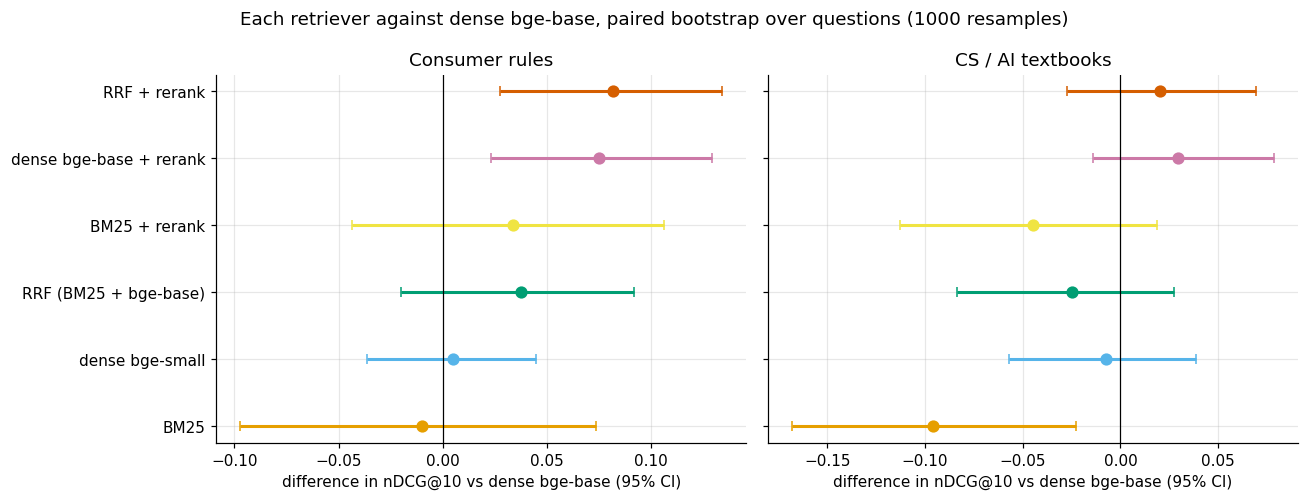

> Highest nDCG@10 on the rules: `RRF + rerank` at +0.082 (95% CI +0.028 to +0.134) against dense bge-base. On the textbooks: `dense bge-base + rerank` at +0.030 (95% CI -0.014 to +0.079) against dense bge-base.

In [12]:
def paired_bootstrap(a, b, n_resamples: int = N_BOOT, seed: int = SEED) -> tuple:
    """Mean of a - b over paired questions and its percentile 95% bootstrap interval."""
    diffs = np.asarray(a, dtype=float) - np.asarray(b, dtype=float)
    idx = np.random.default_rng(seed).integers(0, len(diffs), size=(n_resamples, len(diffs)))
    boot = diffs[idx].mean(axis=1)
    return float(diffs.mean()), float(np.percentile(boot, 2.5)), float(np.percentile(boot, 97.5))


rows = []
for coll in COLLECTION_LABELS:
    ref = per_q[(per_q.collection == coll) & (per_q.config == REFERENCE)].set_index("uid")
    for name in CONFIGS:
        if name == REFERENCE:
            continue
        other = per_q[(per_q.collection == coll) & (per_q.config == name)].set_index("uid").loc[ref.index]
        for m in METRICS:
            d, lo, hi = paired_bootstrap(other[m], ref[m])
            rows.append({"collection": coll, "config": name, "metric": m, "delta": d, "ci_low": lo, "ci_high": hi,
                         "excludes_0": lo > 0 or hi < 0})
boot = pd.DataFrame(rows)


def boot_row(coll: str, name: str, metric: str) -> pd.Series:
    return boot[(boot.collection == coll) & (boot.config == name) & (boot.metric == metric)].iloc[0]


def describe(coll: str, name: str, metric: str) -> str:
    """'+0.050 (95% CI +0.010 to +0.090)' for one comparison with the reference."""
    r = boot_row(coll, name, metric)
    return f"{r.delta:+.3f} (95% CI {r.ci_low:+.3f} to {r.ci_high:+.3f})"


VERDICT_NAMES = {"consumer_rules": "rules", "cs_ai": "textbooks"}


def verdict(name: str, metric: str) -> str:
    """Which of the two collections' intervals exclude zero for one configuration."""
    flags = {c: bool(boot_row(c, name, metric).excludes_0) for c in COLLECTION_LABELS}
    if all(flags.values()):
        return "both intervals exclude zero"
    if not any(flags.values()):
        return "both intervals include zero"
    return f"only the {VERDICT_NAMES[next(c for c, f in flags.items() if f)]} interval excludes zero"


fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
metric = f"nDCG@{K_RANK}"
for ax, coll in zip(axes, COLLECTION_LABELS):
    sub = boot[(boot.collection == coll) & (boot.metric == metric)].reset_index(drop=True)
    for i, r in sub.iterrows():
        ax.errorbar(r.delta, i, xerr=[[r.delta - r.ci_low], [r.ci_high - r.delta]], fmt="o", ms=7, capsize=3, lw=2,
                    color=PALETTE[r.config])
    ax.axvline(0, color="black", lw=0.8)
    ax.set_yticks(range(len(sub)))
    ax.set_yticklabels(sub.config)
    ax.invert_yaxis()
    ax.set_title(COLLECTION_LABELS[coll])
    ax.set_xlabel(f"difference in {metric} vs {REFERENCE} (95% CI)")
fig.suptitle(f"Each retriever against dense bge-base, paired bootstrap over questions ({N_BOOT} resamples)")
plt.tight_layout()
plt.show()
best = {c: table.loc[c][metric].idxmax() for c in COLLECTION_LABELS}


def best_text(coll: str) -> str:
    name = best[coll]
    return f"`{name}`, the reference itself" if name == REFERENCE else f"`{name}` at {describe(coll, name, metric)} against {REFERENCE}"


takeaway(f"Highest {metric} on the rules: {best_text('consumer_rules')}. On the textbooks: {best_text('cs_ai')}.")

In [13]:
boot.pivot_table(index=["collection", "config"], columns="metric", values="delta", sort=False).style.format("{:+.3f}")

## 9. Quality against latency

Reranking costs a cross-encoder pass over 20 chunks per question. The plot shows what that buys. Latency is the mean per query on this session's hardware, excluding model loading and corpus embedding.

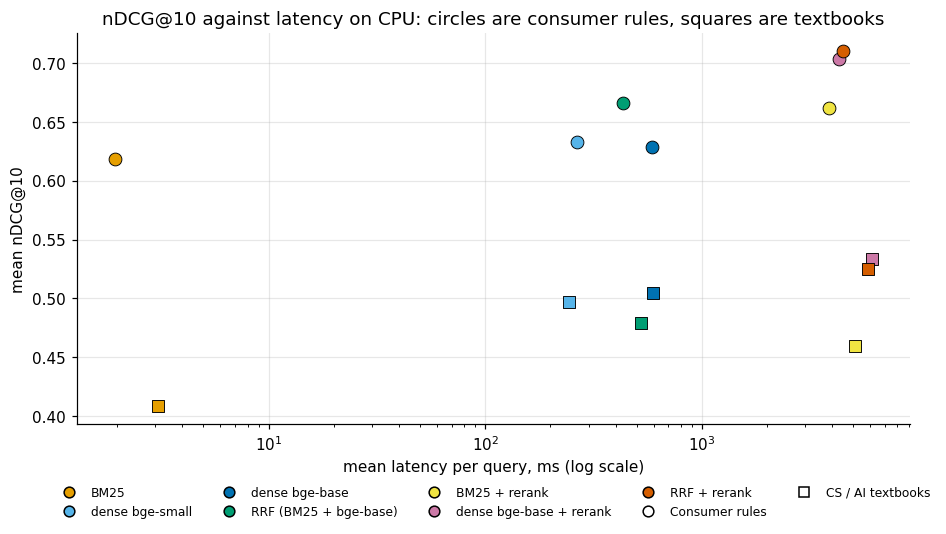

> On this CPU session BM25 answers in 3.1 ms per textbook query, dense bge-base in 592.6 ms and RRF + rerank in 5851.6 ms, of which the cross-encoder takes 90%.

In [14]:
def plot_quality_latency(ax, metric: str = f"nDCG@{K_RANK}", big: bool = False) -> None:
    """Scatter of mean metric against mean latency, one marker per config and collection."""
    markers = {"consumer_rules": "o", "cs_ai": "s"}
    for (coll, name), r in table.iterrows():
        ax.scatter(r.latency_ms, r[metric], s=160 if big else 70, marker=markers[coll], color=PALETTE[name],
                   edgecolor="black", linewidth=0.6, zorder=3)
    ax.set_xscale("log")
    ax.set_xlabel("mean latency per query, ms (log scale)")
    ax.set_ylabel(f"mean {metric}")
    handles = [plt.Line2D([], [], marker="o", ls="", color=PALETTE[n], markeredgecolor="black", ms=9 if big else 7, label=n) for n in CONFIGS]
    handles += [plt.Line2D([], [], marker=markers[c], ls="", color="white", markeredgecolor="black", ms=9 if big else 7,
                           label=COLLECTION_LABELS[c]) for c in COLLECTION_LABELS]
    ax.legend(handles=handles, fontsize=11 if big else 8, loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=5, frameon=False)


fig, ax = plt.subplots(figsize=(9, 5))
plot_quality_latency(ax)
ax.set_title(f"nDCG@{K_RANK} against latency on {DEVICE.upper()}: circles are consumer rules, squares are textbooks")
plt.tight_layout()
plt.show()
lat = table["latency_ms"]
rr_share = per_q[(per_q.collection == "cs_ai") & (per_q.config == "RRF + rerank")].pipe(lambda d: d.ms_rerank.sum() / d.latency_ms.sum())
takeaway(f"On this {DEVICE.upper()} session BM25 answers in {lat.loc[('cs_ai', 'BM25')]:.1f} ms per textbook query, dense bge-base in "
         f"{lat.loc[('cs_ai', 'dense bge-base')]:.1f} ms and RRF + rerank in {lat.loc[('cs_ai', 'RRF + rerank')]:.1f} ms, "
         f"of which the cross-encoder takes {rr_share:.0%}.")

## 10. Where each retriever wins

Means can hide that two retrievers succeed on different questions, which is the reason fusion works at all. For each question, check whether BM25 and dense bge-base put a relevant chunk in their top 5.

In [15]:
def hit5(name: str) -> pd.Series:
    sub = per_q[per_q.config == name].set_index("uid")
    return sub[f"Recall@{K_RECALL}"] > 0


bm, dn, ff = hit5("BM25"), hit5("dense bge-base"), hit5("RRF (BM25 + bge-base)")
overlap = pd.DataFrame({"BM25 hit": bm, "dense hit": dn, "RRF hit": ff, "collection": per_q[per_q.config == "BM25"].set_index("uid").collection})
hit_or_miss = {True: "hit", False: "miss"}
counts = (overlap.assign(**{"BM25 top 5": overlap["BM25 hit"].map(hit_or_miss), "dense bge-base top 5": overlap["dense hit"].map(hit_or_miss)})
          .groupby(["collection", "BM25 top 5", "dense bge-base top 5"]).size().unstack(fill_value=0))
counts

dense bge-base top 5       hit  miss
collection     BM25 top 5           
consumer_rules hit          37     2
               miss          4     3
cs_ai          hit          45     2
               miss          9     4

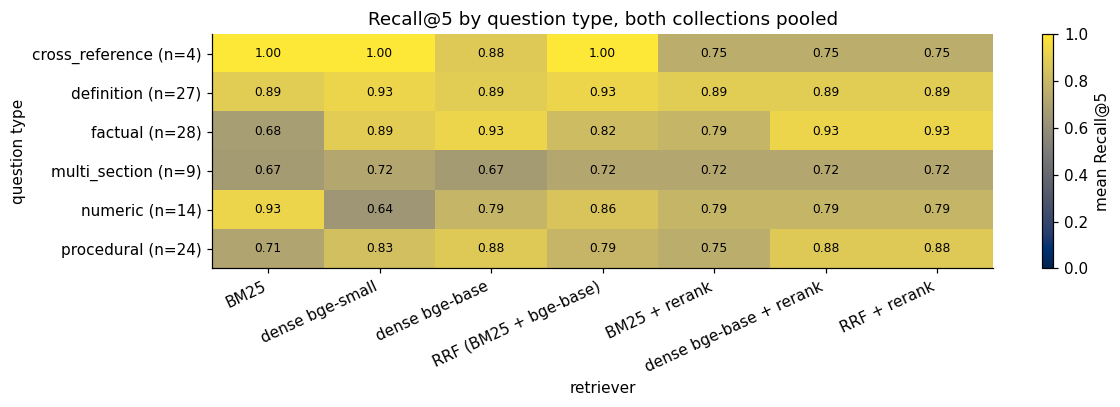

> BM25 finds a relevant chunk in the top 5 for 4 questions where dense bge-base does not, and dense finds 13 that BM25 misses; RRF hits 92 of 106 questions.

In [16]:
by_type = per_q.pivot_table(index="type", columns="config", values=f"Recall@{K_RECALL}", aggfunc="mean")[list(CONFIGS)]
n_type = per_q[per_q.config == "BM25"].groupby("type").size()
fig, ax = plt.subplots(figsize=(11, 3.8))
im = ax.imshow(by_type.values, cmap="cividis", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(CONFIGS)))
ax.set_xticklabels(list(CONFIGS), rotation=25, ha="right")
ax.set_yticks(range(len(by_type)))
ax.set_yticklabels([f"{t} (n={n_type[t]})" for t in by_type.index])
for i in range(by_type.shape[0]):
    for j in range(by_type.shape[1]):
        v = by_type.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8, color="white" if v < 0.55 else "black")
ax.grid(False)
ax.set_xlabel("retriever")
ax.set_ylabel("question type")
ax.set_title(f"Recall@{K_RECALL} by question type, both collections pooled")
fig.colorbar(im, ax=ax, label=f"mean Recall@{K_RECALL}")
plt.tight_layout()
plt.show()
only_bm = int((bm & ~dn).sum())
only_dn = int((dn & ~bm).sum())
takeaway(f"BM25 finds a relevant chunk in the top 5 for {only_bm} questions where dense bge-base does not, and dense finds {only_dn} that BM25 misses; "
         f"RRF hits {int(ff.sum())} of {len(ff)} questions.")

In [17]:
# Cover image for the Kaggle listing: quality against latency at 1280 x 720 pixels
fig, ax = plt.subplots(figsize=(12.8, 7.2), dpi=100)
plot_quality_latency(ax, big=True)
ax.set_title(f"Seven retrievers: nDCG@{K_RANK} against latency (circles: consumer rules, squares: textbooks)", fontsize=17)
ax.xaxis.label.set_fontsize(15)
ax.yaxis.label.set_fontsize(15)
ax.tick_params(labelsize=13)
fig.tight_layout()
fig.savefig(WORK_DIR / "cover.png", dpi=100)
plt.close(fig)
print(f"notebook run time so far: {(time.time() - NOTEBOOK_START) / 60:.1f} min")

notebook run time so far: 59.6 min


## 11. What we found

In [18]:
m_n, m_r = f"nDCG@{K_RANK}", f"Recall@{K_RECALL}"
rrf_name = "RRF (BM25 + bge-base)"
findings = [
    f"Dense bge-base reached nDCG@10 of {table.loc[('consumer_rules', REFERENCE), m_n]:.3f} on the consumer rules and "
    f"{table.loc[('cs_ai', REFERENCE), m_n]:.3f} on the textbooks. BM25 with the statute-aware tokenizer reached "
    f"{table.loc[('consumer_rules', 'BM25'), m_n]:.3f} and {table.loc[('cs_ai', 'BM25'), m_n]:.3f}, a difference of "
    f"{describe('consumer_rules', 'BM25', m_n)} on the rules and {describe('cs_ai', 'BM25', m_n)} on the textbooks; {verdict('BM25', m_n)}.",
    f"Fusing BM25 and dense bge-base with RRF changed nDCG@10 by {describe('consumer_rules', rrf_name, m_n)} on the rules and "
    f"{describe('cs_ai', rrf_name, m_n)} on the textbooks; {verdict(rrf_name, m_n)}.",
    f"Reranking the fused top 20 with MiniLM changed nDCG@10 by {describe('consumer_rules', 'RRF + rerank', m_n)} on the rules and "
    f"{describe('cs_ai', 'RRF + rerank', m_n)} on the textbooks ({verdict('RRF + rerank', m_n)}), at "
    f"{lat.loc[('cs_ai', 'RRF + rerank')]:.0f} ms per textbook query on {DEVICE.upper()} against {lat.loc[('cs_ai', REFERENCE)]:.0f} ms for dense retrieval alone.",
    f"Swapping bge-base for bge-small (384 instead of 768 dimensions) changed Recall@5 by {describe('consumer_rules', 'dense bge-small', m_r)} "
    f"on the rules and {describe('cs_ai', 'dense bge-small', m_r)} on the textbooks; {verdict('dense bge-small', m_r)}.",
]
display(Markdown("\n\n".join(findings)))

Dense bge-base reached nDCG@10 of 0.628 on the consumer rules and 0.504 on the textbooks. BM25 with the statute-aware tokenizer reached 0.618 and 0.408, a difference of -0.010 (95% CI -0.097 to +0.073) on the rules and -0.096 (95% CI -0.168 to -0.023) on the textbooks; only the textbooks interval excludes zero.

Fusing BM25 and dense bge-base with RRF changed nDCG@10 by +0.037 (95% CI -0.020 to +0.092) on the rules and -0.025 (95% CI -0.083 to +0.027) on the textbooks; both intervals include zero.

Reranking the fused top 20 with MiniLM changed nDCG@10 by +0.082 (95% CI +0.028 to +0.134) on the rules and +0.020 (95% CI -0.027 to +0.069) on the textbooks (only the rules interval excludes zero), at 5852 ms per textbook query on CPU against 593 ms for dense retrieval alone.

Swapping bge-base for bge-small (384 instead of 768 dimensions) changed Recall@5 by +0.033 (95% CI -0.043 to +0.109) on the rules and -0.058 (95% CI -0.150 to +0.033) on the textbooks; both intervals include zero.

### Limitations

106 answerable questions split over two small corpora give wide intervals, and seven configurations times four metrics make some chance "wins" likely. All questions are used, with no separate tuning split, because nothing here is tuned (the constants are the usual defaults: k1 = 1.5, b = 0.75, RRF k = 60, top 20 reranked). The questions were drafted by a 3B model from single passages, which favours retrievers that match the passage's wording. Latency is measured on whatever hardware this session has and excludes network and model loading.

### Ideas to try

- Try `BAAI/bge-reranker-base` as `RERANKER`, or raise `RERANK_N` to 50.
- Replace RRF with a weighted sum of min-max normalised scores and tune the weight on the dev split.
- Turn off the reference tokens in `tokenize` and measure what they add on the consumer rules.
- Run the ablation on the `fixed_512` chunks by changing `CHUNKER`.

### The VeriDex series

1. [Chunking legal text for RAG: structure-aware vs fixed vs semantic chunks](https://www.kaggle.com/code/swapnilshukla007/chunking-legal-text-for-rag)
2. BM25, dense, RRF fusion and cross-encoder reranking (this notebook)
3. [Catching unsupported sentences: NLI faithfulness checks for RAG answers](https://www.kaggle.com/code/swapnilshukla007/nli-faithfulness-checks-for-rag-answers)
4. [Teaching a RAG system to abstain: thresholds, coverage and selective accuracy](https://www.kaggle.com/code/swapnilshukla007/teaching-a-rag-system-to-abstain)
5. [RAG in a browser tab: int8 embedding indexes and the size-recall trade-off](https://www.kaggle.com/code/swapnilshukla007/rag-in-a-browser-tab-int8-embedding-indexes)

If you spot a mistake or get different numbers, please say so in the comments; an upvote helps other people find the notebook.